In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
fashion_mnist = tf.keras.datasets.fashion_mnist
(train_images,train_labels),(test_images,test_labels) = fashion_mnist.load_data()
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
print("The train images shape is ",train_images.shape)
print("The test images shape is ", test_images.shape)

The train images shape is  (60000, 28, 28)
The test images shape is  (10000, 28, 28)


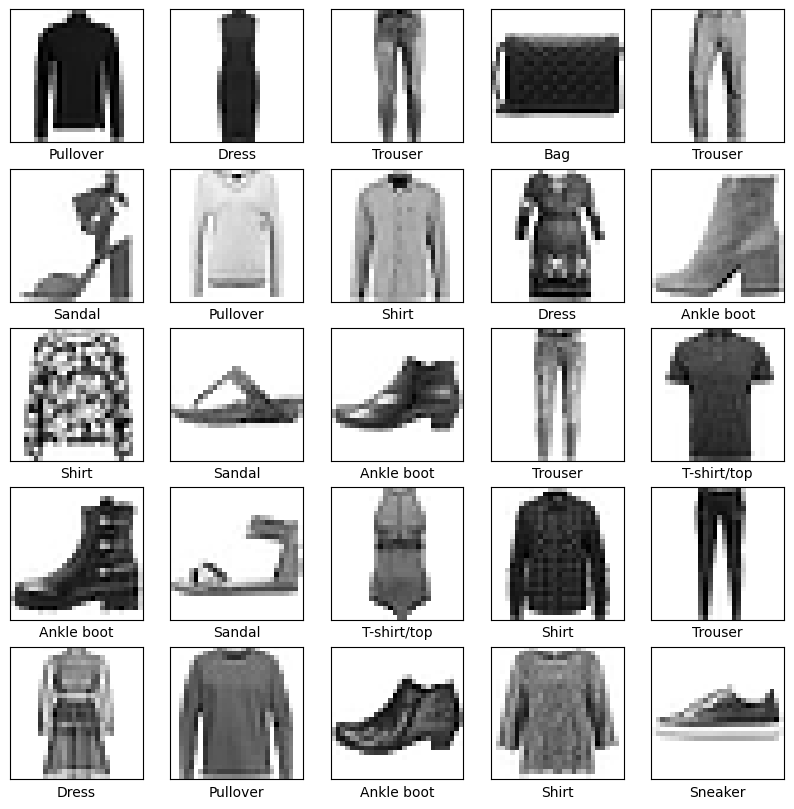

In [ ]:
import random
from random import randint
plt.figure(figsize=(10,10))
for i in range (25):
  plt.subplot(5,5,i+1)
  random_no = randint(0,len(train_images))
  plt.imshow(train_images[random_no],cmap=plt.cm.binary)
  plt.xlabel(class_names[train_labels[random_no]])
  plt.xticks([])
  plt.yticks([])
plt.show()

Reshaping Image Data for Modelling

In [ ]:
train_images_reshaped = train_images.reshape(60000,28,28,1)
test_images_reshaped = test_images.reshape(10000,28,28,1)

Build CNN Model Architecture

In [ ]:
INPUT_SHAPE = (28,28,1)
model = tf.keras.models.Sequential()
#define cov-pool layers-set 1
model.add(tf.keras.layers.Conv2D(filters = 32, kernel_size = (3,3),strides = (1,1),activation = "relu",padding = "valid",input_shape = INPUT_SHAPE))
model.add(tf.keras.layers.MaxPool2D(pool_size = (2,2)))
#define cov-pool layers -set 2
model.add(tf.keras.layers.Conv2D(filters = 32, strides =(1,1),kernel_size=(3,3),activation = "relu",padding = "valid",input_shape = INPUT_SHAPE))
model.add(tf.keras.layers.MaxPool2D(pool_size = (2,2)))
#define dense layers
model.add(tf.keras.layers.Flatten())
# add dense layers with some dropout
model.add(tf.keras.layers.Dense(256,activation= "relu"))
model.add(tf.keras.layers.Dropout(0.3))
model.add(tf.keras.layers.Dense(256,activation = "relu"))
model.add(tf.keras.layers.Dropout(0.3))
model.add(tf.keras.layers.Dense(10,activation = "softmax"))


/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


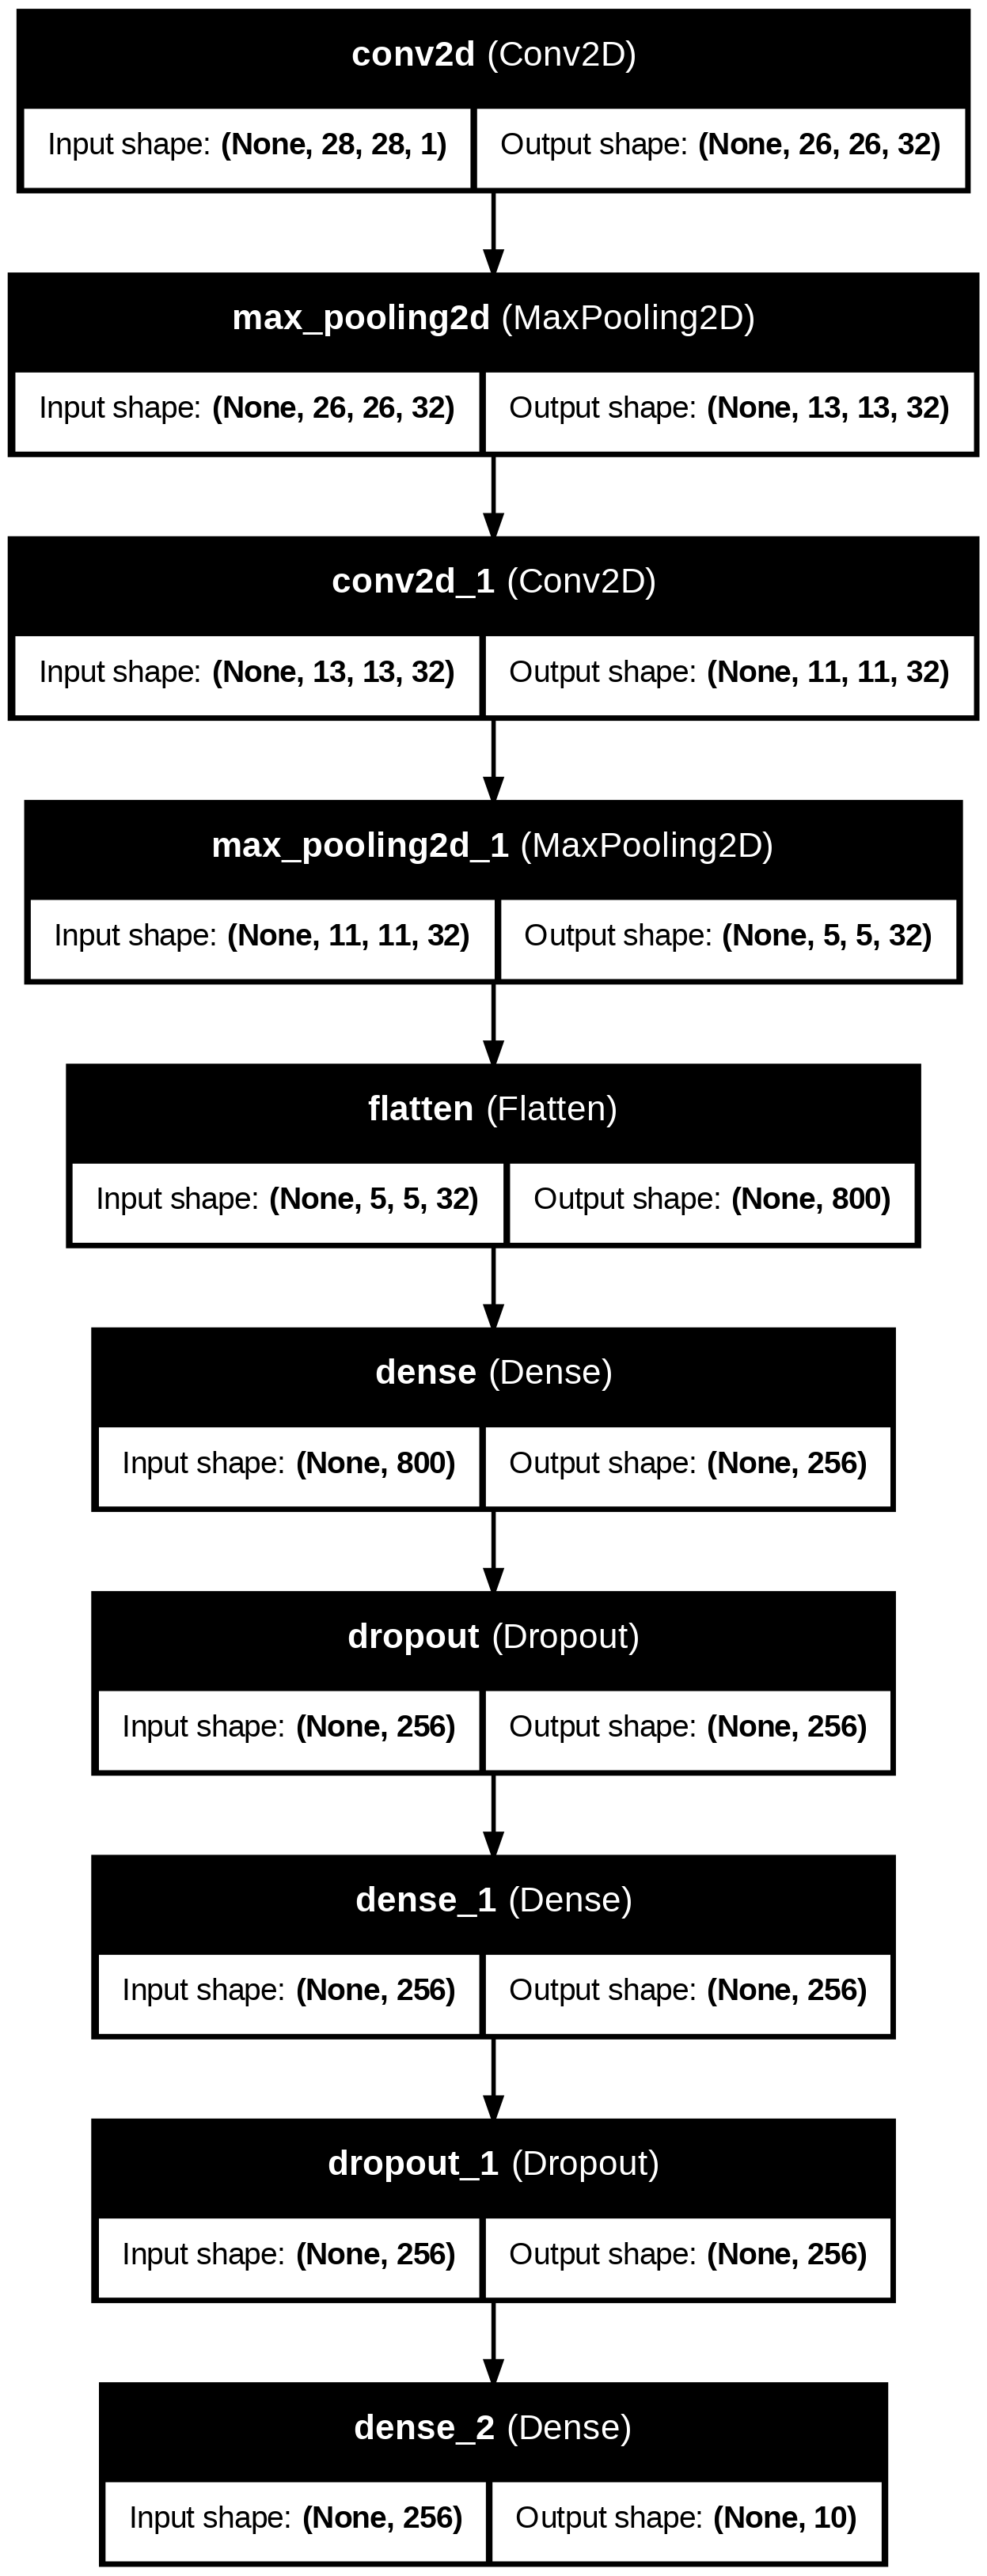

In [ ]:
from tensorflow.keras.utils import plot_model
plot_model(model,show_shapes = True, show_layer_names = True)

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 800)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       205,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 282,986 (1.08 MB)

 Trainable params: 282,986 (1.08 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(optimizer = "adam",loss = "sparse_categorical_crossentropy",metrics = ['accuracy'])


### Model Training

In [ ]:
train_images_scaled = train_images_reshaped/255.0
test_images_scaled = test_images_reshaped/255.0
from tensorflow.keras.callbacks import EarlyStopping
early_stopping = EarlyStopping(patience = 3, monitor = "val_loss")
model.fit(train_images_reshaped,train_labels, validation_split = 0.2, epochs = 100, batch_size = 32, callbacks = [early_stopping],verbose = 1)


Epoch 1/100
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.7066 - loss: 1.2198 - val_accuracy: 0.8427 - val_loss: 0.4278
Epoch 2/100
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8363 - loss: 0.4513 - val_accuracy: 0.8568 - val_loss: 0.3724
Epoch 3/100
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8545 - loss: 0.3894 - val_accuracy: 0.8632 - val_loss: 0.3755
Epoch 4/100
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8625 - loss: 0.3737 - val_accuracy: 0.8773 - val_loss: 0.3389
Epoch 5/100
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8753 - loss: 0.3400 - val_accuracy: 0.8737 - val_loss: 0.3385
Epoch 6/100
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.8795 - loss: 0.3266 - val_accuracy: 0.8790 - val_loss: 0.3273
Epoch 7/100
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.8844 - loss: 0.3150 - val_accuracy: 0.8737 - val_loss: 0.3441
Epoch 8/100
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.8890 - los

### Plotting Learning Curves

<Axes: >

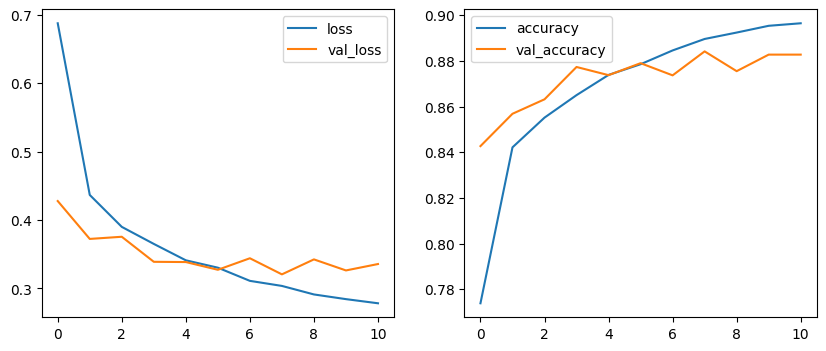

In [ ]:
fig, ax = plt.subplots(1,2, figsize = (10,4))
import pandas as pd
history_df = pd.DataFrame(model.history.history)
history_df[['loss','val_loss']].plot(kind = "line",ax = ax[0])
history_df[['accuracy','val_accuracy']].plot(kind = "line",ax = ax[1])

### Evaluate Model Performance on Test Data

In [ ]:
predictions = model.predict(test_images_reshaped)
predictions[:5]

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


array([[1.8938164e-18, 6.3655672e-21, 6.5894531e-17, 3.6610134e-17,
        2.6040524e-16, 1.7920324e-09, 3.7565630e-17, 1.7540058e-09,
        7.8282150e-17, 1.0000000e+00],
       [1.5047664e-06, 2.7352374e-14, 9.9563771e-01, 1.9028292e-13,
        5.6118415e-06, 9.3732145e-18, 4.3551684e-03, 8.7965824e-20,
        6.5076261e-10, 5.8140809e-18],
       [2.3347997e-17, 1.0000000e+00, 1.2674118e-22, 2.5386806e-15,
        1.5653031e-20, 2.5630951e-30, 4.8046936e-19, 1.9622395e-32,
        3.7671839e-31, 1.8512056e-30],
       [5.6549139e-15, 1.0000000e+00, 2.1547523e-18, 1.6871825e-11,
        1.6794446e-15, 1.6190891e-25, 1.7495975e-14, 2.4551015e-27,
        2.7772592e-24, 1.4475379e-25],
       [8.0917135e-02, 7.4224751e-08, 3.5219245e-02, 4.6701872e-04,
        1.0315555e-02, 2.2116160e-07, 8.7295121e-01, 6.7141235e-07,
        1.2894184e-04, 4.6890353e-08]], dtype=float32)

In [ ]:
prediction_labels = np.argmax(predictions, axis = 1)
prediction_labels[:5]

array([9, 2, 1, 1, 6])

In [ ]:
from sklearn.metrics import confusion_matrix,classification_report
print(classification_report(test_labels,prediction_labels , target_names = class_names))

              precision    recall  f1-score   support

 T-shirt/top       0.85      0.80      0.83      1000
     Trouser       0.99      0.97      0.98      1000
    Pullover       0.81      0.78      0.80      1000
       Dress       0.90      0.89      0.89      1000
        Coat       0.78      0.81      0.79      1000
      Sandal       0.98      0.95      0.97      1000
       Shirt       0.64      0.67      0.65      1000
     Sneaker       0.94      0.95      0.94      1000
         Bag       0.96      0.98      0.97      1000
  Ankle boot       0.94      0.97      0.96      1000

    accuracy                           0.88     10000
   macro avg       0.88      0.88      0.88     10000
weighted avg       0.88      0.88      0.88     10000



### FINE-TURNING A PRE-TRAINED VGG-19 CNN  MODE

In [ ]:
train_images_3ch = np.stack([train_images]*3,axis = -1)
test_images_3ch = np.stack([test_images]*3,axis = -1)

### Resizing Image Data For Modelling

In [ ]:
import cv2
def resize_image_array(img, img_size_dims):
  img = cv2.resize(img,dsize = img_size_dims,interpolation = cv2.INTER_CUBIC)
  img = np.array(img,dtype = np.float32)
  return img

In [ ]:
%%time

IMG_DIMS = (32, 32)

train_images_3ch = np.array([resize_image_array(img, img_size_dims=IMG_DIMS) for img in train_images_3ch])
test_images_3ch = np.array([resize_image_array(img, img_size_dims=IMG_DIMS) for img in test_images_3ch])

print('\nTrain_images.shape: {}, of {}'.format(train_images_3ch.shape, train_images_3ch.dtype))
print('Test_images.shape: {}, of {}'.format(test_images_3ch.shape, test_images_3ch.dtype))


Train_images.shape: (60000, 32, 32, 3), of float32
Test_images.shape: (10000, 32, 32, 3), of float32
CPU times: user 1.26 s, sys: 537 ms, total: 1.8 s
Wall time: 1.89 s


In [ ]:
INPUT_SHAPE = (32,32,3)
#Get the VGG-19 model
vgg_layers = tf.keras.applications.vgg19.VGG19(weights = 'imagenet',include_top = False,input_shape = INPUT_SHAPE)
vgg_layers.summary()

80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "vgg19"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 32, 32, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 8, 8, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 8, 8, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 8, 8, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv4 (Conv2D)           │ (None, 8, 8, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 4, 4, 512)      │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 4, 4, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 4, 4, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv4 (Conv2D)           │ (None, 4, 4, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 2, 2, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 2, 2, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 2, 2, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 2, 2, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv4 (Conv2D)           │ (None, 2, 2, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 1, 1, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,024,384 (76.39 MB)

 Trainable params: 20,024,384 (76.39 MB)

 Non-trainable params: 0 (0.00 B)

### Set layers to trainable to enable fine-tuning.

In [ ]:
for layer in vgg_layers.layers:
  layer.trainable = True

### Build CNN model on top of VGG19

In [ ]:
# define sequential model
model = tf.keras.models.Sequential()
model.add(vgg_layers)
# add a faltten layer
model.add(tf.keras.layers.Flatten())
# add dense layers with some drop out
model.add(tf.keras.layers.Dense(256,activation = "relu"))
model.add(tf.keras.layers.Dropout(0.3))
model.add(tf.keras.layers.Dense(256,activation = "relu"))
model.add(tf.keras.layers.Dropout(0.3))
model.add(tf.keras.layers.Dense(10,activation = "softmax"))

### Compiling the model

In [ ]:
model.compile(optimizer = "adam", loss = "sparse_categorical_crossentropy",metrics = ['accuracy'])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg19 (Functional)              │ (None, 1, 1, 512)      │    20,024,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,224,074 (77.15 MB)

 Trainable params: 20,224,074 (77.15 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
train_images_3ch_reshaped = train_images_3ch/255.0
test_images_3ch_reshaped = test_images_3ch/255.0
es_callbacks = EarlyStopping(patience = 3, monitor = "val_loss")
model.fit(train_images_3ch_reshaped,train_labels,validation_split = 0.1, epochs = 100, batch_size = 32,verbose = 1,callbacks = [es_callbacks])


Epoch 1/100
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 116s 62ms/step - accuracy: 0.3992 - loss: 1.4301 - val_accuracy: 0.7188 - val_loss: 0.7216
Epoch 2/100
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 125s 56ms/step - accuracy: 0.7328 - loss: 0.7222 - val_accuracy: 0.8005 - val_loss: 0.6071
Epoch 3/100
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 142s 56ms/step - accuracy: 0.7801 - loss: 0.6338 - val_accuracy: 0.8145 - val_loss: 0.5223
Epoch 4/100
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 142s 56ms/step - accuracy: 0.8099 - loss: 0.5305 - val_accuracy: 0.8500 - val_loss: 0.4171
Epoch 5/100
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 142s 56ms/step - accuracy: 0.8344 - loss: 0.4858 - val_accuracy: 0.8708 - val_loss: 0.4277
Epoch 6/100
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 141s 56ms/step - accuracy: 0.8655 - loss: 0.4031 - val_accuracy: 0.8810 - val_loss: 0.3631
Epoch 7/100
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 96s 57ms/step - accuracy: 0.8768 - loss: 0.3715 - val_accuracy: 0.8772 - val_loss: 0.3565
Epoch 8/100
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 141s 56ms/step - acc

Plot learning Curves

<Axes: >

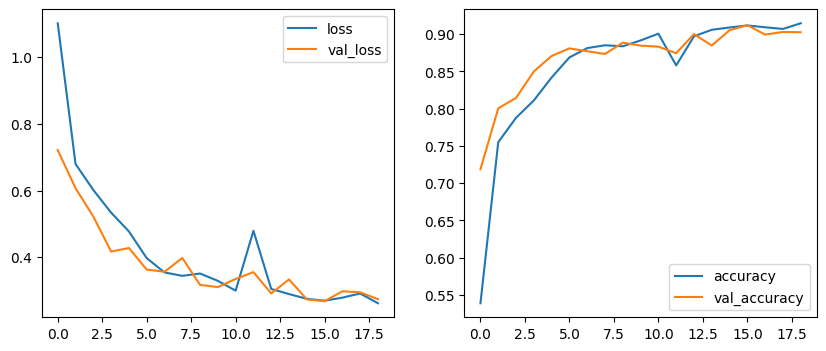

In [ ]:
historys_df = pd.DataFrame(model.history.history)
fig, ax = plt.subplots(1,2, figsize = (10,4))
historys_df[['loss','val_loss']].plot(kind = "line" ,ax = ax[0])
historys_df[['accuracy','val_accuracy']].plot(kind = "line",ax = ax[1])

### Model Evaluation

In [ ]:
test_images_3ch_reshaped = test_images_3ch/255.0
predictions = model.predict(test_images_3ch_reshaped)
prediction_labels = np.argmax(predictions, axis = 1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step


In [ ]:
prediction_labels[:5]

array([9, 2, 1, 1, 4])

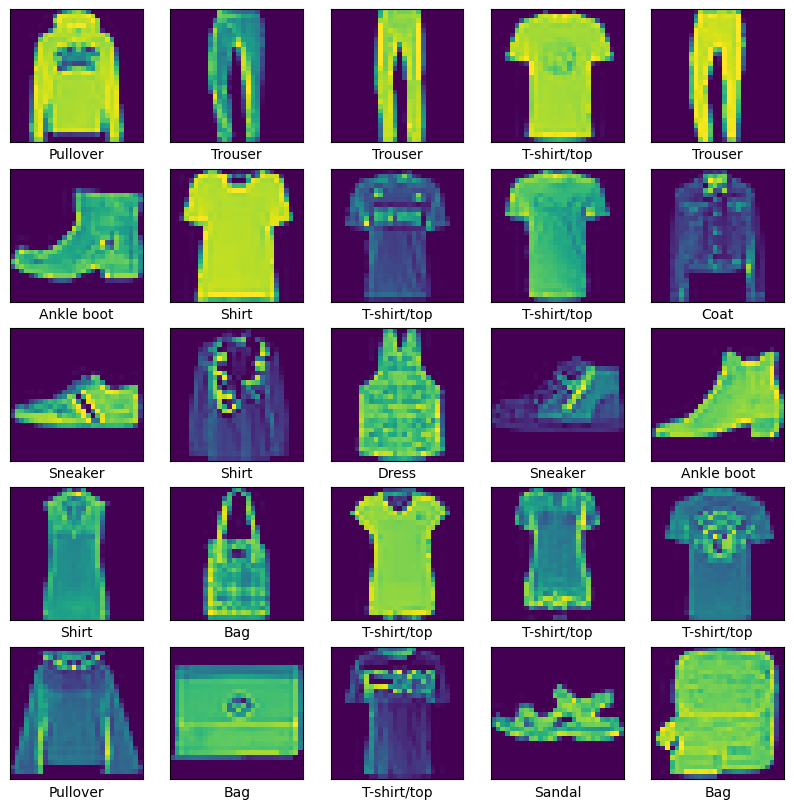

In [ ]:
plt.figure(figsize=(10,10))
for i in range(25):
  plt.subplot(5,5,i+1)
  random_no = randint(1,len(test_images))
  plt.imshow(test_images[random_no])
  plt.xlabel(class_names[test_labels[random_no]])
  plt.xticks([])
  plt.yticks([])
plt.show()

In [ ]:
print(classification_report(test_labels,prediction_labels,target_names = class_names))

              precision    recall  f1-score   support

 T-shirt/top       0.83      0.84      0.84      1000
     Trouser       0.99      0.98      0.99      1000
    Pullover       0.88      0.86      0.87      1000
       Dress       0.86      0.93      0.89      1000
        Coat       0.86      0.84      0.85      1000
      Sandal       0.99      0.98      0.98      1000
       Shirt       0.72      0.67      0.70      1000
     Sneaker       0.93      0.97      0.95      1000
         Bag       0.98      0.98      0.98      1000
  Ankle boot       0.97      0.95      0.96      1000

    accuracy                           0.90     10000
   macro avg       0.90      0.90      0.90     10000
weighted avg       0.90      0.90      0.90     10000



By using a Pretrained model for our model we see that the performance increased.

### Exporting Model for Deployment

In [ ]:


model.save('my_model.h5')
